# 📊 Práctica 2 · Encargo 1: Ganancias por Región
### ETL en memoria con Pandas — Northwind (MySQL 8.0)

**Objetivo:** determinar las ganancias por región documentando cada paso hasta la consulta final: la línea base contable, el intento ingenuo que no cuadra, la causa raíz del desvío y la construcción de la solución validada al centavo.

**Criterio de diseño:** el fan-out relacional se resuelve en memoria. El SQL contra MySQL queda limitado a extracción directa (0 JOINs) y controles puntuales (≤ 2 JOINs); las dimensiones, el cruzamiento y la agregación se ejecutan vectorizados en Pandas.

## 0. Entorno y conexión

In [1]:
import os
import time
from decimal import Decimal, ROUND_HALF_UP

import numpy as np
import pandas as pd
import sqlalchemy as sa
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

DB_HOST = os.getenv("PRACTICA2_DB_HOST", "127.0.0.1")
DB_PORT = int(os.getenv("PRACTICA2_DB_PORT", "3308"))
DB_NAME = os.getenv("PRACTICA2_DB_NAME", "northwind")
# PRACTICA2_DB_USER alimenta MYSQL_USER en docker-compose.yml, asi que el rol de
# conexion del notebook viaja en una variable aparte.
DB_USER = os.getenv("PRACTICA2_DB_CONNECT_USER", "root")
DB_PASS = os.getenv("PRACTICA2_DB_ROOT_PASSWORD",
                     os.getenv("PRACTICA2_DB_PASSWORD", "rootpassword"))

CONNECTION_URL = f"mysql+pymysql://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
engine = sa.create_engine(CONNECTION_URL, pool_pre_ping=True)

with engine.connect() as conn:
    version = conn.execute(sa.text("SELECT VERSION()")).scalar()
print(f"✅ Conexión exitosa a MySQL {version} en {DB_HOST}:{DB_PORT}/{DB_NAME}")

✅ Conexión exitosa a MySQL 8.0.46 en 127.0.0.1:3308/northwind


## 1. Fase 1: Reconocimiento y extracción

Se extraen únicamente las columnas que intervienen en el análisis. `employees.Photo` y `categories.Picture` son blobs binarios: cargarlos multiplicaría el I/O de red sin aportar nada a la métrica.

In [2]:
with engine.connect() as conn:
    df_region   = pd.read_sql(sa.text("SELECT RegionID, RegionDescription FROM region"), conn)
    df_terr     = pd.read_sql(sa.text("SELECT TerritoryID, RegionID FROM territories"), conn)
    df_emp_terr = pd.read_sql(sa.text("SELECT EmployeeID, TerritoryID FROM employeeterritories"), conn)
    df_emp      = pd.read_sql(sa.text("SELECT EmployeeID, FirstName, LastName, Title FROM employees"), conn)
    df_orders   = pd.read_sql(sa.text("SELECT OrderID, EmployeeID, OrderDate, Freight FROM orders"), conn)
    df_od       = pd.read_sql(sa.text("SELECT OrderID, ProductID, UnitPrice, Quantity, Discount FROM `order details`"), conn)

df_region["RegionID"]     = df_region["RegionID"].astype("int32")
df_terr["RegionID"]       = df_terr["RegionID"].astype("int32")
df_emp_terr["EmployeeID"] = df_emp_terr["EmployeeID"].astype("int32")
df_emp["EmployeeID"]      = df_emp["EmployeeID"].astype("int32")
df_orders["OrderID"]      = df_orders["OrderID"].astype("int32")
df_orders["EmployeeID"]   = df_orders["EmployeeID"].astype("int32")
df_orders["OrderDate"]    = pd.to_datetime(df_orders["OrderDate"])
df_orders["Freight"]      = pd.to_numeric(df_orders["Freight"], errors="coerce")
df_od["OrderID"]          = df_od["OrderID"].astype("int32")
df_od["Quantity"]         = pd.to_numeric(df_od["Quantity"], errors="coerce")
df_od["UnitPrice"]        = pd.to_numeric(df_od["UnitPrice"], errors="coerce")
df_od["Discount"]         = pd.to_numeric(df_od["Discount"], errors="coerce")

# Importe de línea sin redondeo intermedio: el redondeo se aplica al presentar,
# no al acumular (evita error de centavos acumulado).
df_od["monto_linea"] = df_od["UnitPrice"] * df_od["Quantity"] * (1 - df_od["Discount"])

for nombre, d in [("region", df_region), ("territories", df_terr), ("employeeterritories", df_emp_terr),
                  ("employees", df_emp), ("orders", df_orders), ("order details", df_od)]:
    print(f"  • df_{nombre.replace(' ','_'):22s} {d.shape[0]:>6,} filas x {d.shape[1]} columnas")

  • df_region                      4 filas x 2 columnas
  • df_territories                53 filas x 2 columnas
  • df_employeeterritories        49 filas x 2 columnas
  • df_employees                   9 filas x 4 columnas
  • df_orders                    830 filas x 4 columnas
  • df_order_details           2,155 filas x 6 columnas


### 1.1 Normalización detectada en el origen

`RegionDescription` es `VARCHAR(50)` con relleno de espacios heredado de la migración original: sin `TRIM()` las etiquetas salen distintas de lo esperado y las comparaciones por string fallan.

In [3]:
display(df_region.assign(
    longitud=[len(x) for x in df_region["RegionDescription"]],
    descripcion_limpia=df_region["RegionDescription"].str.strip(),
).rename(columns={"RegionDescription": "descripcion_con_espacios"}))

df_region["RegionDescription"] = df_region["RegionDescription"].str.strip()
print("Regiones tras normalizar:", list(df_region["RegionDescription"]))

,RegionID,descripcion_con_espacios,longitud,descripcion_limpia
0,1,Eastern ...,50,Eastern
1,2,Westerns ...,50,Westerns
2,3,Northern ...,50,Northern
3,4,Southern ...,50,Southern


Regiones tras normalizar: ['Eastern', 'Westerns', 'Northern', 'Southern']


## 2. Fase 2: Línea base contable

Ninguna agrupación por región es válida si su suma no coincide con el total facturado. Se fija la cifra de control antes de construir cualquier reporte.

In [4]:
with engine.connect() as conn:
    sql_ground_truth = float(conn.execute(sa.text(
        "SELECT ROUND(SUM(UnitPrice * Quantity * (1 - Discount)), 2) FROM `order details`"
    )).scalar())

pandas_ground_truth = round(float(df_od["monto_linea"].sum()), 2)
unidades = int(df_od["Quantity"].sum())
pedidos  = int(df_od["OrderID"].nunique())

assert abs(sql_ground_truth - pandas_ground_truth) < 0.01, "Discrepancia SQL vs Pandas en la línea base"

print(f"💵 Línea Base contable (SQL, 0 JOINs) : ${sql_ground_truth:,.2f}")
print(f"🐼 Línea Base contable (Pandas)       : ${pandas_ground_truth:,.2f}")
print(f"📦 Unidades: {unidades:,}   |   🧾 Pedidos: {pedidos:,}")
print(f"✅ Certificación: el control contable es exactamente ${sql_ground_truth:,.2f}.")

💵 Línea Base contable (SQL, 0 JOINs) : $1,354,458.59
🐼 Línea Base contable (Pandas)       : $1,354,458.59
📦 Unidades: 51,317   |   🧾 Pedidos: 830
✅ Certificación: el control contable es exactamente $1,354,458.59.


In [5]:
# Auditoría de fletes: es una métrica de nivel 'pedido', no de 'línea'.
fletes_reales = round(float(df_orders["Freight"].sum()), 2)
facturacion_integrada = round(pandas_ground_truth + fletes_reales, 2)
lineas_por_pedido = round(len(df_od) / len(df_orders), 2)

print(f"🚚 Fletes facturados (nivel pedido) : ${fletes_reales:,.2f}")
print(f"🧾 Líneas de detalle por pedido (prom.): {lineas_por_pedido}")
print(f"💰 Facturación integrada (productos + fletes): ${facturacion_integrada:,.2f}")

🚚 Fletes facturados (nivel pedido) : $64,942.69
🧾 Líneas de detalle por pedido (prom.): 2.6
💰 Facturación integrada (productos + fletes): $1,419,401.28


## 3. Fase 3: El intento ingenuo

El reflejo natural es enlazar las tablas en cadena y agregar. En SQL son 6 JOINs; en Pandas es un merge en cadena. Se reproduce ese camino para medir su error.

In [6]:
# El merge contra `employeeterritories` NO lleva validate= porque su
# cardinalidad many-to-many ES el defecto que se está reproduciendo.
# Los demás cruces sí se validan, para aislar una única variable.
df_ingenuo = (
    df_od.merge(df_orders[["OrderID", "EmployeeID"]], on="OrderID", validate="m:1")
          .merge(df_emp[["EmployeeID"]], on="EmployeeID", validate="m:1")
          .merge(df_emp_terr, on="EmployeeID")
          .merge(df_terr, on="TerritoryID", validate="m:1")
          .merge(df_region[["RegionID", "RegionDescription"]], on="RegionID", validate="m:1")
)

naive = df_ingenuo.groupby("RegionID", as_index=False).agg(
    ganancia_ingenua=("monto_linea", "sum"),
    filas_generadas=("monto_linea", "size"),
).merge(df_region[["RegionID", "RegionDescription"]], on="RegionID")
naive["RegionDescription"] = naive["RegionDescription"].str.strip()
naive["ganancia_ingenua"] = naive["ganancia_ingenua"].round(2)

total_ingenuo = round(float(naive["ganancia_ingenua"].sum()), 2)
desfase = round(total_ingenuo - pandas_ground_truth, 2)

display(naive.rename(columns={"RegionDescription": "region", "filas_generadas": "lineas_infladas"}))

print(f"❌ Suma con cruce ingenuo : ${total_ingenuo:,.2f}")
print(f"💵 Línea base contable    : ${pandas_ground_truth:,.2f}")
print(f"⚠️  Desfase               : +${desfase:,.2f}  (+{(desfase/pandas_ground_truth)*100:.1f}%)")
print(f"🔁 Filas de detalle leídas: {len(df_od):,}  →  filas tras el cruce: {len(df_ingenuo):,}  (×{len(df_ingenuo)/len(df_od):.2f})")

,RegionID,ganancia_ingenua,lineas_infladas,region
0,1,"2,928,068.84",4456,Eastern
1,2,"1,803,950.40",2600,Westerns
2,3,"1,113,952.12",1789,Northern
3,4,"852,205.20",1284,Southern


❌ Suma con cruce ingenuo : $6,698,176.56
💵 Línea base contable    : $1,354,458.59
⚠️  Desfase               : +$5,343,717.97  (+394.5%)
🔁 Filas de detalle leídas: 2,155  →  filas tras el cruce: 10,129  (×4.70)


## 4. Fase 4: Auditoría forense

La pregunta de causa raíz: ¿de dónde sale exactamente cada centavo de más?

In [7]:
# 4.1 Multiplicidad de la tabla puente empleado -> territorio
df_terr_emp = (df_emp_terr.groupby("EmployeeID", as_index=False)
                         .agg(territorios=("TerritoryID", "nunique"))
                         .merge(df_emp, on="EmployeeID"))

df_terr_emp["nombre"] = df_terr_emp["FirstName"] + " " + df_terr_emp["LastName"]
display(df_terr_emp[["EmployeeID", "nombre", "Title", "territorios"]]
        .sort_values("territorios", ascending=False)
        .rename(columns={"Title": "cargo", "territorios": "territorios_asignados"}))

,EmployeeID,nombre,cargo,territorios_asignados
6,7,Robert King,Sales Representative,10
8,9,Anne Dodsworth,Sales Representative,7
1,2,Andrew Fuller,"Vice President, Sales",7
4,5,Steven Buchanan,Sales Manager,7
5,6,Michael Suyama,Sales Representative,5
7,8,Laura Callahan,Inside Sales Coordinator,4
2,3,Janet Leverling,Sales Representative,4
3,4,Margaret Peacock,Sales Representative,3
0,1,Nancy Davolio,Sales Representative,2


In [8]:
# 4.2 Unicidad regional por empleado: si cada vendedor pertenece a una sola
# región, la relación region <- empleado es unívoca y el fan-out es evitable.
regiones_por_emp = (df_emp_terr.merge(df_terr[["TerritoryID", "RegionID"]], on="TerritoryID", validate="m:1")
                                .groupby("EmployeeID")["RegionID"]
                                .nunique()
                                .rename("regiones_distintas"))

assert (regiones_por_emp == 1).all(), "Un empleado opera en más de una región: el modelo de una región por empleado no aplica"

display(regiones_por_emp.to_frame().join(df_emp.set_index("EmployeeID")[["FirstName", "LastName"]]))
print("✅ Todos los empleados pertenecen a exactamente 1 región.")
print("   → La multiplicidad proviene de los TERRITORIOS dentro de su misma región,")
print("     no de un cruce interregional. Se corrige desacoplando empleado -> región.")

,regiones_distintas,FirstName,LastName
EmployeeID,,,
1,1,Nancy,Davolio
2,1,Andrew,Fuller
3,1,Janet,Leverling
4,1,Margaret,Peacock
5,1,Steven,Buchanan
6,1,Michael,Suyama
7,1,Robert,King
8,1,Laura,Callahan
9,1,Anne,Dodsworth


✅ Todos los empleados pertenecen a exactamente 1 región.
   → La multiplicidad proviene de los TERRITORIOS dentro de su misma región,
     no de un cruce interregional. Se corrige desacoplando empleado -> región.


In [9]:
# 4.3 Conciliación matemática: la venta real de cada empleado × su número de
# territorios debe reconstruir su aporte en el cruce ingenuo, al centavo.
venta_real_emp = (df_od.merge(df_orders[["OrderID", "EmployeeID"]], on="OrderID", validate="m:1")
                        .groupby("EmployeeID")["monto_linea"].sum())

recon = (df_terr_emp.set_index("EmployeeID")
         .join(venta_real_emp.rename("venta_real"))
         .join(regiones_por_emp.rename("region_id")))
recon["venta_real"] = recon["venta_real"].round(2)
recon["factor"]    = recon["territorios"].astype(int)
recon["ingenuo"]   = (recon["venta_real"] * recon["factor"]).round(2)
recon["region"]    = recon["region_id"].map(df_region.set_index("RegionID")["RegionDescription"])

ingenuo_por_emp = df_ingenuo.groupby("EmployeeID")["monto_linea"].sum().reindex(recon.index)
assert np.allclose(recon["ingenuo"].values, np.round(ingenuo_por_emp.values, 2)), \
    "La reconciliación por empleado no reproduce el cruce ingenuo"

display(recon[["nombre", "region", "territorios", "venta_real", "ingenuo"]]
        .sort_values(["region", "venta_real"], ascending=[True, False])
        .rename(columns={"nombre": "empleado", "territorios": "factor_multiplicacion"}))
print("🎉 Cada centavo del error ingenuo queda reconstruido por empleado.")

,empleado,region,factor_multiplicacion,venta_real,ingenuo
EmployeeID,,,,,
4,Margaret Peacock,Eastern,3,"250,187.45","750,562.35"
3,Janet Leverling,Eastern,4,"213,051.30","852,205.20"
1,Nancy Davolio,Eastern,2,"202,143.71","404,287.42"
2,Andrew Fuller,Eastern,7,"177,749.26","1,244,244.82"
7,Robert King,Eastern,10,"141,295.99","1,412,959.90"
8,Laura Callahan,Eastern,4,"133,301.03","533,204.12"
9,Anne Dodsworth,Eastern,7,"82,964.00","580,748.00"
6,Michael Suyama,Eastern,5,"78,198.10","390,990.50"
5,Steven Buchanan,Eastern,7,"75,567.75","528,974.25"


🎉 Cada centavo del error ingenuo queda reconstruido por empleado.


In [10]:
# 4.4 La trampa de los fletes: al unir cabecera con detalle, Freight se
# replica una vez por cada línea del pedido (cardinalidad 1:m).
fletes_con_join = round(float(df_orders.merge(df_od[["OrderID"]], on="OrderID", validate="1:m")["Freight"].sum()), 2)

print(f"🚚 Fletes reales (nivel pedido)           : ${fletes_reales:,.2f}")
print(f"🚚 Fletes si se suman tras unir con detalle: ${fletes_con_join:,.2f}")
print(f"⚠️  Inflación de fletes: +${fletes_con_join - fletes_reales:,.2f} (+{((fletes_con_join/fletes_reales)-1)*100:.1f}%)")
print("   → Regla: las métricas de nivel 'pedido' se pre-agregan a nivel OrderID.")

🚚 Fletes reales (nivel pedido)           : $64,942.69
🚚 Fletes si se suman tras unir con detalle: $207,306.10
⚠️  Inflación de fletes: +$142,363.41 (+219.2%)
   → Regla: las métricas de nivel 'pedido' se pre-agregan a nivel OrderID.


## 5. Fase 5: Construcción iterativa de la solución

In [11]:
# 5.1 Desacoplamiento: un único registro por empleado con su región.
df_emp_region = (df_emp_terr
                 .merge(df_terr[["TerritoryID", "RegionID"]], on="TerritoryID", validate="m:1")
                 [["EmployeeID", "RegionID"]]
                 .drop_duplicates())

assert df_emp_region["EmployeeID"].is_unique, "La relación empleado -> región no es unívoca"
assert len(df_emp_region) == df_emp["EmployeeID"].nunique(), "Faltan empleados en el mapeo"

display(df_emp_region.merge(df_emp[["EmployeeID", "FirstName", "LastName"]], on="EmployeeID")
        .assign(nombre=lambda d: d["FirstName"] + " " + d["LastName"])
        [["EmployeeID", "nombre", "RegionID"]]
        .merge(df_region[["RegionID", "RegionDescription"]], on="RegionID")
        .rename(columns={"RegionDescription": "region"})
        .sort_values("EmployeeID"))
print(f"✅ Mapeo limpio: {len(df_emp_region)} empleados → {df_emp_region['RegionID'].nunique()} regiones (1:1)")

,EmployeeID,nombre,RegionID,region
3,1,Nancy Davolio,1,Eastern
0,2,Andrew Fuller,1,Eastern
6,3,Janet Leverling,4,Southern
5,4,Margaret Peacock,1,Eastern
1,5,Steven Buchanan,1,Eastern
8,6,Michael Suyama,2,Westerns
7,7,Robert King,2,Westerns
4,8,Laura Callahan,3,Northern
2,9,Anne Dodsworth,3,Northern


✅ Mapeo limpio: 9 empleados → 4 regiones (1:1)


In [12]:
# 5.2 Ruta directa: líneas -> pedido -> empleado -> región, ya desacoplado.
df_ventas_ok = (df_od.merge(df_orders[["OrderID", "EmployeeID"]], on="OrderID", validate="m:1")
                     .merge(df_emp_region, on="EmployeeID", validate="m:1"))

ruta_directa = (df_ventas_ok.merge(df_region[["RegionID", "RegionDescription"]], on="RegionID", validate="m:1")
                          .groupby(["RegionID", "RegionDescription"], as_index=False)
                          .agg(ganancias=("monto_linea", "sum")))
ruta_directa["ganancias"] = ruta_directa["ganancias"].round(2)

total_ok = round(float(ruta_directa["ganancias"].sum()), 2)
assert abs(total_ok - pandas_ground_truth) < 0.01, "La ruta desacoplada no cuadra con la línea base"

display(ruta_directa.rename(columns={"RegionDescription": "region"}).sort_values("ganancias", ascending=False))
print(f"✅ Suma de las 4 regiones: ${total_ok:,.2f}  |  Línea base: ${pandas_ground_truth:,.2f}  |  Descuadre: ${total_ok - pandas_ground_truth:,.2f}")

,RegionID,region,ganancias
0,1,Eastern,"705,648.17"
1,2,Westerns,"219,494.09"
2,3,Northern,"216,265.03"
3,4,Southern,"213,051.30"


✅ Suma de las 4 regiones: $1,354,458.59  |  Línea base: $1,354,458.59  |  Descuadre: $0.00


### 5.3 Ruta optimizada: pre-agregar en el motor

Para bases grandes, traer las 2 155 líneas para sumarlas en el cliente es desperdicio: el motor puede devolver directamente las 830 filas a nivel pedido. Se miden las dos estrategias end-to-end sobre la conexión real.

In [13]:
def cronometrar(fn, repeticiones=10):
    fn()  # calentamiento
    t0 = time.perf_counter()
    for _ in range(repeticiones):
        fn()
    return (time.perf_counter() - t0) / repeticiones

# (a) El motor pre-agrupa y devuelve 830 filas.
t_preagregado = cronometrar(lambda: pd.read_sql(sa.text(
    "SELECT OrderID, SUM(Quantity) AS unidades, "
    "SUM(UnitPrice * Quantity * (1 - Discount)) AS venta "
    "FROM `order details` GROUP BY OrderID"), engine))

# (b) El motor devuelve las 2 155 líneas y Pandas agrega en el cliente.
def traer_detalle_y_agregar():
    d = pd.read_sql(sa.text(
        "SELECT OrderID, Quantity, UnitPrice, Discount FROM `order details`"), engine)
    d["monto"] = d["UnitPrice"] * d["Quantity"] * (1 - d["Discount"])
    return d.groupby("OrderID", as_index=False).agg(unidades=("Quantity", "sum"), venta=("monto", "sum"))

t_detalle = cronometrar(traer_detalle_y_agregar)

df_pedido = (df_od.groupby("OrderID", as_index=False)
                    .agg(unidades=("Quantity", "sum"), venta=("monto_linea", "sum")))

print(f"🔁 Pre-agregado en MySQL (GROUP BY OrderID) : {t_preagregado*1000:8.2f} ms  → {len(df_pedido):,} filas")
print(f"🔁 Detalle crudo + groupby en Pandas        : {t_detalle*1000:8.2f} ms  → {len(df_pedido):,} filas")
print(f"📉 Filas que bajan al cliente: {len(df_od):,} líneas  →  {len(df_pedido):,} pedidos  ({len(df_pedido)/len(df_od)*100:.1f}%)")
print(f"⚡ Ventaja del pre-agregado en servidor: {(t_detalle/t_preagregado):.2f}× más rápido")

🔁 Pre-agregado en MySQL (GROUP BY OrderID) :    12.17 ms  → 830 filas
🔁 Detalle crudo + groupby en Pandas        :    23.33 ms  → 830 filas
📉 Filas que bajan al cliente: 2,155 líneas  →  830 pedidos  (38.5%)
⚡ Ventaja del pre-agregado en servidor: 1.92× más rápido


In [14]:
# 5.4 La ruta optimizada completa: 1 merge 1:1 con pedidos, 1 merge 1:1 con región.
df_ruta_opt = (df_pedido
               .merge(df_orders[["OrderID", "EmployeeID", "Freight"]], on="OrderID", validate="1:1")
               .merge(df_emp_region, on="EmployeeID", validate="m:1"))

ruta_opt = (df_ruta_opt.merge(df_region[["RegionID", "RegionDescription"]], on="RegionID", validate="m:1")
                        .groupby(["RegionID", "RegionDescription"], as_index=False)
                        .agg(unidades=("unidades", "sum"),
                             ganancias=("venta", "sum"),
                             fletes=("Freight", "sum")))
ruta_opt["ganancias"] = ruta_opt["ganancias"].round(2)
ruta_opt["fletes"]    = ruta_opt["fletes"].round(2)

assert abs(round(float(ruta_opt["ganancias"].sum()), 2) - pandas_ground_truth) < 0.01, \
    "La ruta optimizada no cuadra con la línea base"

display(ruta_opt.rename(columns={"RegionDescription": "region"}).sort_values("ganancias", ascending=False))
print(f"✅ Ruta optimizada: ${round(float(ruta_opt['ganancias'].sum()),2):,.2f} — idéntica a la ruta directa y a la línea base.")
print("   Ventaja estructural: la relación pedido↔región es 1:1, no existe fan-out posible.")

,RegionID,region,unidades,ganancias,fletes
0,1,Eastern,26701,"705,648.17","32,797.90"
1,2,Westerns,8181,"219,494.09","10,445.91"
2,3,Northern,8583,"216,265.03","10,814.14"
3,4,Southern,7852,"213,051.30","10,884.74"


✅ Ruta optimizada: $1,354,458.59 — idéntica a la ruta directa y a la línea base.
   Ventaja estructural: la relación pedido↔región es 1:1, no existe fan-out posible.


### 5.5 Inclusión de todas las regiones

Un reporte gerencial debe listar las 4 regiones aunque una tuviera $0.00, en lugar de omitirla del análisis.

In [15]:
df_reporte = (df_region[["RegionID", "RegionDescription"]]
              .rename(columns={"RegionDescription": "region"})
              .merge(ruta_opt[["RegionID", "unidades", "ganancias", "fletes"]], on="RegionID", how="left")
              .fillna({"unidades": 0, "ganancias": 0.0, "fletes": 0.0}))
df_reporte["ganancias"] = df_reporte["ganancias"].round(2)
df_reporte["fletes"]    = df_reporte["fletes"].round(2)

assert len(df_reporte) == df_region["RegionID"].nunique(), "Se perdió alguna región en el reporte"
print("Regiones en el reporte:", list(df_reporte["region"]))

Regiones en el reporte: ['Eastern', 'Westerns', 'Northern', 'Southern']


## 6. Fase 6: Criterios de negocio

In [16]:
# 6.1 Auditoría interna de aporte: qué vendedor genera los ingresos de cada región.
df_empleado_region = (df_emp_region
                       .merge(df_emp[["EmployeeID", "FirstName", "LastName", "Title"]], on="EmployeeID", validate="1:1")
                       .assign(nombre=lambda d: d["FirstName"] + " " + d["LastName"]))

df_por_empleado = (df_ruta_opt
                   .merge(df_empleado_region[["EmployeeID", "nombre", "Title"]], on="EmployeeID", validate="m:1")
                   .groupby(["RegionID", "nombre", "Title"], as_index=False)
                   .agg(pedidos=("OrderID", "nunique"),
                        unidades=("unidades", "sum"),
                        venta_neta=("venta", "sum")))
df_por_empleado["venta_neta"] = df_por_empleado["venta_neta"].round(2)
df_por_empleado = df_por_empleado.merge(df_region[["RegionID", "RegionDescription"]], on="RegionID")
df_por_empleado["RegionDescription"] = df_por_empleado["RegionDescription"].str.strip()
df_por_empleado = df_por_empleado.rename(columns={"RegionDescription": "region", "Title": "cargo"})
df_por_empleado = df_por_empleado[["RegionID", "region", "nombre", "cargo", "pedidos", "unidades", "venta_neta"]]

assert abs(round(float(df_por_empleado["venta_neta"].sum()), 2) - pandas_ground_truth) < 0.01
display(df_por_empleado.sort_values(["RegionID", "venta_neta"], ascending=[True, False]))

,RegionID,region,nombre,cargo,pedidos,unidades,venta_neta
1,1,Eastern,Margaret Peacock,Sales Representative,156,9798,"250,187.45"
2,1,Eastern,Nancy Davolio,Sales Representative,123,7812,"202,143.71"
0,1,Eastern,Andrew Fuller,"Vice President, Sales",96,6055,"177,749.26"
3,1,Eastern,Steven Buchanan,Sales Manager,42,3036,"75,567.75"
5,2,Westerns,Robert King,Sales Representative,72,4654,"141,295.99"
4,2,Westerns,Michael Suyama,Sales Representative,67,3527,"78,198.10"
7,3,Northern,Laura Callahan,Inside Sales Coordinator,104,5913,"133,301.03"
6,3,Northern,Anne Dodsworth,Sales Representative,43,2670,"82,964.00"
8,4,Southern,Janet Leverling,Sales Representative,127,7852,"213,051.30"


In [17]:
# 6.2 Criterio 2: facturación integrada (productos netos + fletes), con fletes
# pre-agregados a nivel OrderID para no duplicarlos.
df_criterio2 = (df_reporte[["RegionID", "region", "unidades", "ganancias", "fletes"]]
                .assign(facturacion_total=lambda d: (d["ganancias"] + d["fletes"]).round(2)))
df_criterio2["facturacion_total"] = df_criterio2["facturacion_total"].round(2)

assert round(float(df_criterio2["facturacion_total"].sum()), 2) == facturacion_integrada
display(df_criterio2)
print(f"💰 Facturación integrada: ${round(float(df_criterio2['facturacion_total'].sum()),2):,.2f} "
      f"(= ${pandas_ground_truth:,.2f} productos + ${fletes_reales:,.2f} fletes)")

,RegionID,region,unidades,ganancias,fletes,facturacion_total
0,1,Eastern,26701,"705,648.17","32,797.90","738,446.07"
1,2,Westerns,8181,"219,494.09","10,445.91","229,940.00"
2,3,Northern,8583,"216,265.03","10,814.14","227,079.17"
3,4,Southern,7852,"213,051.30","10,884.74","223,936.04"


💰 Facturación integrada: $1,419,401.28 (= $1,354,458.59 productos + $64,942.69 fletes)


## 7. Fase 7: Entregables finales

In [18]:
# 7.1 Respuesta concisa al requerimiento: ganancias por región.
df_final_simple = (df_reporte[["RegionID", "region", "ganancias"]]
                   .rename(columns={"RegionID": "id_region", "ganancias": "ganancias_totales"})
                   .sort_values("ganancias_totales", ascending=False)
                   .reset_index(drop=True))
display(df_final_simple)

,id_region,region,ganancias_totales
0,1,Eastern,"705,648.17"
1,2,Westerns,"219,494.09"
2,3,Northern,"216,265.03"
3,4,Southern,"213,051.30"


In [19]:
# 7.2 Master Query ejecutiva: KPIs de dirección comercial.
def r_up(v):
    return float(Decimal(str(v)).quantize(Decimal("0.01"), rounding=ROUND_HALF_UP)) if pd.notna(v) else 0.0

vendedores_por_region = df_emp_region.groupby("RegionID")["EmployeeID"].nunique()
pedidos_por_region     = df_ruta_opt.groupby("RegionID")["OrderID"].nunique()

df_master = df_criterio2.copy()
df_master["fuerza_ventas"] = df_master["RegionID"].map(vendedores_por_region).fillna(0).astype(int)
df_master["pedidos"]       = df_master["RegionID"].map(pedidos_por_region).fillna(0).astype(int)
df_master["participacion"] = (df_master["ganancias"] / pandas_ground_truth * 100).round(2)
df_master["ticket_promedio"] = (df_master["ganancias"] / df_master["pedidos"].replace(0, np.nan)).fillna(0).map(r_up)

df_master = df_master.rename(columns={
    "RegionID": "ID Región", "region": "Región", "fuerza_ventas": "Fuerza de Ventas (Vendedores)",
    "pedidos": "Total Pedidos", "unidades": "Unidades Vendidas",
    "ganancias": "Ganancias Productos ($)", "fletes": "Fletes Facturados ($)",
    "facturacion_total": "Facturación Total ($)", "participacion": "% Participación Ventas",
    "ticket_promedio": "Ticket Promedio ($)"})

df_master = df_master[["ID Región", "Región", "Fuerza de Ventas (Vendedores)", "Total Pedidos",
                       "Unidades Vendidas", "Ganancias Productos ($)", "Fletes Facturados ($)",
                       "Facturación Total ($)", "% Participación Ventas", "Ticket Promedio ($)"]] \
             .sort_values("Ganancias Productos ($)", ascending=False).reset_index(drop=True)

display(df_master)

,ID Región,Región,Fuerza de Ventas (Vendedores),Total Pedidos,Unidades Vendidas,Ganancias Productos ($),Fletes Facturados ($),Facturación Total ($),% Participación Ventas,Ticket Promedio ($)
0,1,Eastern,4,417,26701,"705,648.17","32,797.90","738,446.07",52.10,"1,692.20"
1,2,Westerns,2,139,8181,"219,494.09","10,445.91","229,940.00",16.21,"1,579.09"
2,3,Northern,2,147,8583,"216,265.03","10,814.14","227,079.17",15.97,"1,471.19"
3,4,Southern,1,127,7852,"213,051.30","10,884.74","223,936.04",15.73,"1,677.57"


## 8. Fase 8: Conciliación contable al 100%

In [20]:
suma_regiones  = round(float(df_final_simple["ganancias_totales"].sum()), 2)
descuadre      = round(suma_regiones - pandas_ground_truth, 2)

cuadre = pd.DataFrame([
    {"Concepto": "1. Ganancias sumadas por región", "Monto ($)": suma_regiones,
     "Auditoría": "Agregación de las 4 regiones del reporte final"},
    {"Concepto": "2. Línea base oficial (order details)", "Monto ($)": pandas_ground_truth,
     "Auditoría": "Control contable directo sobre la tabla transaccional"},
    {"Concepto": "3. Descuadre", "Monto ($)": descuadre,
     "Auditoría": "Diferencia = $0.00 -> conciliación al 100%"},
])

assert descuadre == 0.0, f"Conciliación fallida: descuadre de ${descuadre:,.2f}"
assert round(float(df_criterio2["facturacion_total"].sum()), 2) == facturacion_integrada

display(cuadre)
print("🎉 Conciliación exitosa: el 100% de la facturación está atribuida, sin pérdidas ni duplicaciones.")

,Concepto,Monto ($),Auditoría
0,1. Ganancias sumadas por región,"1,354,458.59",Agregación de las 4 regiones del reporte final
1,2. Línea base oficial (order details),"1,354,458.59",Control contable directo sobre la tabla transa...
2,3. Descuadre,0.00,Diferencia = $0.00 -> conciliación al 100%


🎉 Conciliación exitosa: el 100% de la facturación está atribuida, sin pérdidas ni duplicaciones.


## 9. Fase 9: Visualización e insights

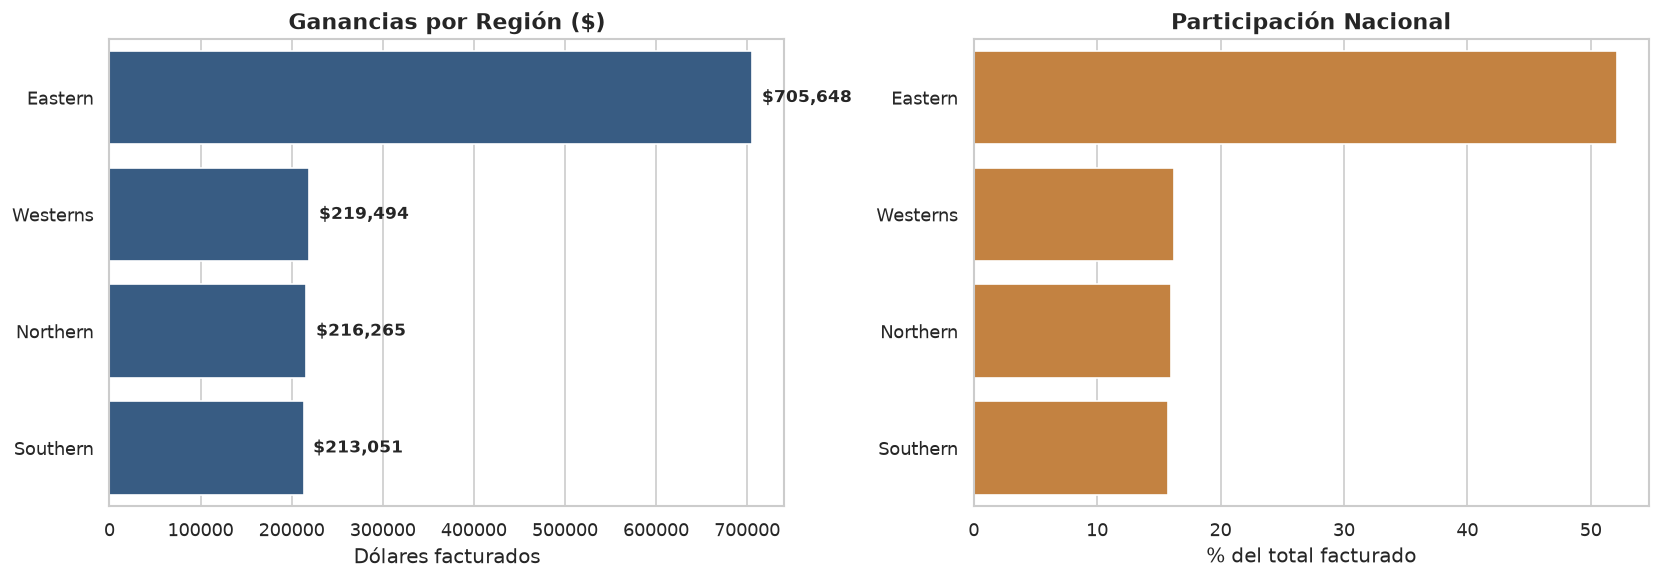

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_viz = df_master.sort_values("Ganancias Productos ($)", ascending=False)
sns.barplot(data=df_viz, y="Región", x="Ganancias Productos ($)", ax=axes[0], color="#2b5c8f")
axes[0].set_title("Ganancias por Región ($)", fontsize=13, weight="bold")
axes[0].set_xlabel("Dólares facturados")
axes[0].set_ylabel("")

for i, v in enumerate(df_viz["Ganancias Productos ($)"]):
    axes[0].text(v + df_viz["Ganancias Productos ($)"].max() * 0.015, i, f"${v:,.0f}",
                 va="center", fontsize=10, weight="bold")

sns.barplot(data=df_viz, y="Región", x="% Participación Ventas", ax=axes[1], color="#d9822b")
axes[1].set_title("Participación Nacional", fontsize=13, weight="bold")
axes[1].set_xlabel("% del total facturado")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

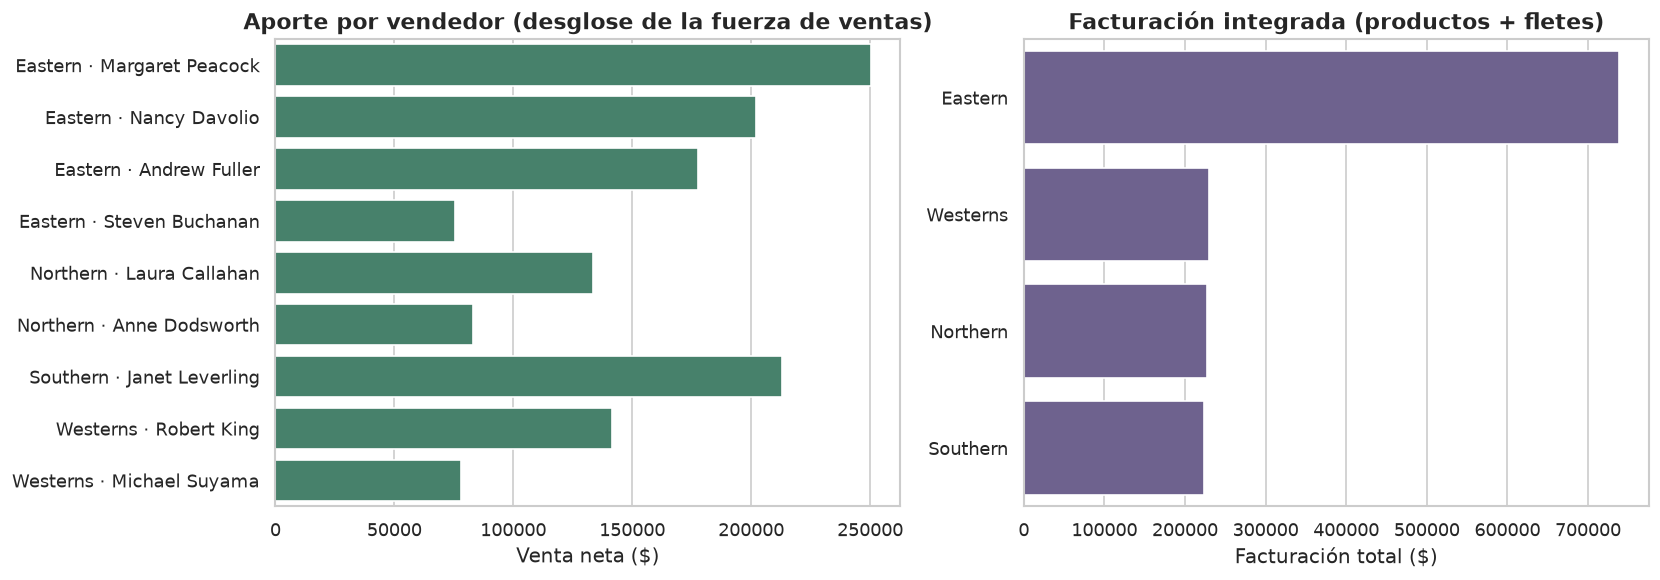

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Aporte por vendedor dentro de cada región
df_ap = df_por_empleado.copy()
df_ap["etiqueta"] = df_ap["region"] + " · " + df_ap["nombre"]
df_ap = df_ap.sort_values(["region", "venta_neta"], ascending=[True, False])
sns.barplot(data=df_ap, y="etiqueta", x="venta_neta", ax=axes[0], color="#3d8b6d")
axes[0].set_title("Aporte por vendedor (desglose de la fuerza de ventas)", fontsize=13, weight="bold")
axes[0].set_xlabel("Venta neta ($)")
axes[0].set_ylabel("")

# Facturación integrada por región
df_viz2 = df_master.sort_values("Facturación Total ($)", ascending=False)
sns.barplot(data=df_viz2, y="Región", x="Facturación Total ($)", ax=axes[1], color="#6b5b95")
axes[1].set_title("Facturación integrada (productos + fletes)", fontsize=13, weight="bold")
axes[1].set_xlabel("Facturación total ($)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 10. Conclusiones

### 📈 Resultados

1. **Eastern concentra el 52.1% de la facturación** ($705,648.17) con 4 de los 9 vendedores y 417 de los 830 pedidos; el resto se reparte de forma homogénea entre las otras tres regiones ($213k–$219k), una dispersión de apenas 3.3× entre la mayor y la menor.
2. El cruce ingenuo infla el resultado en **+$5,343,717.97 (+394.5%)**. La causa raíz no es un error de filtros sino un fan-out de cardinalidad: cada pedido se replica tantas veces como territorios tiene asignados su vendedor (×10 para Robert King, ×2 para Nancy Davolio).
3. La relación **empleado → región es unívoca** (0 de 9 empleados con más de una región): por eso el fan-out es eliminable con una simple proyección `DISTINCT`, sin perder ni reasignar un solo pedido.
4. Los fletes exigen un segundo cuidado: sumarlos tras unir con el detalle los infla de $64,942.69 a $207,306.10 (+219%) porque cada pedido tiene 2.59 líneas en promedio.

### 🏛️ Comparativa de arquitectura

| Dimensión | SQL encadenado (6 JOINs) | ETL en Pandas (este notebook) |
| :--- | :--- | :--- |
| Fan-out | Explícito, invisible en el plan | Detectado por cardinalidad: `validate=` y comparación de `groupby().size()` contra el origen |
| Filas en memoria | 2 155 → 10 129 tras el cruce | 2 155 → 830 (pre-agregación en el motor) |
| Riesgo de duplicación de fletes | Requiere subconsulta agrupada | Eliminado por construcción: flete y venta viajan a nivel `OrderID` |
| Cifras de control | Subconsultas anidadas repetidas en cada verificación | Una sola línea base reutilizada por todos los asserts |
| Portabilidad | Acoplada al motor | Las validaciones son código, ejecutables contra cualquier motor |